# Week 8 Lab Exercise — ARIA v5.0: The Matai'an Three-Act Auditor
# 第八週課堂練習 — ARIA v5.0：馬太鞍三幕稽核器

**Guided lab worksheet** — follow along with the instructor's Demo notebook and fill in the TODO cells.
**引導式練習** — 跟著老師的 Demo 操作，完成 TODO 標記的程式碼。

**Case / 案例**: 2025 Matai'an Creek Barrier Lake Event（馬太鞍溪堰塞湖事件）

---

### Class rhythm / 課程節奏

| Phase / 階段 | Content / 內容 | Cells | Time / 時間 |
|---|---|---|---|
| **Lab 1** | Spectral Detective 光譜偵探 | [S1]–[S6] | 35 min |
| **Lab 2** | Three-Act Audit 三幕稽核 | [S7]–[S15] | 50 min |


## Lab 1 — Environment + Three-Act STAC Scene Selection
## Lab 1 — 環境設定 + 三幕 STAC 影像選擇


In [1]:
# [S1] Environment setup — fill in the imports and STAC client
# TODO: import pystac_client, planetary_computer as pc, stackstac, rioxarray as rxr
# TODO: import xarray as xr, numpy as np, pandas as pd, matplotlib.pyplot as plt
# TODO: import geopandas as gpd; from shapely.geometry import Point

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pystac_client
import planetary_computer as pc
import stackstac
import rioxarray as rxr
import xarray as xr
import geopandas as gpd
from shapely.geometry import Point


# Microsoft JhengHei for Chinese labels
plt.rcParams["font.sans-serif"] = ["Microsoft JhengHei", "PingFang TC", "sans-serif"]
plt.rcParams["axes.unicode_minus"] = False

# TODO: Connect to Planetary Computer
catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=pc.sign_inplace,
)

# --- IMPORTANT: MPC-friendly search pattern ---
# MPC's STAC API sometimes returns 504 "maximum allowed time" errors when you
# combine bbox + date + server-side query={"eo:cloud_cover": {"lt": N}}.
# Safer pattern: skip the server-side query, cap max_items, and filter
# cloud_cover CLIENT-SIDE. Wrap the whole thing in a retry loop.
#
# Reference implementation (uncomment and adapt):
#
def robust_search(bbox, datetime_range, cloud_max=30, max_items=60, tries=3):
    for attempt in range(tries):
        try:
            search = catalog.search(
                collections=["sentinel-2-l2a"],
                bbox=bbox,
                datetime=datetime_range,
                max_items=max_items,
            )
            items = list(search.items())
            items = [i for i in items if i.properties.get("eo:cloud_cover", 100) < cloud_max]
            items.sort(key=lambda i: i.properties["eo:cloud_cover"])
            return items
        except Exception as e:
            time.sleep(2 ** attempt)
    raise RuntimeError("STAC search failed 3x")

# AOI — Matai'an catchment (upper Wanrong → downstream Guangfu)
MATAIAN_BBOX = [121.28, 23.56, 121.52, 23.76]
WANTED_BANDS = ["B02", "B03", "B04", "B08", "B11", "B12"]

# --- Fill these in after Step A.3 (reproducible scene IDs) ---
PRE_ITEM_ID  = "FILL_IN_AFTER_QA"
MID_ITEM_ID  = "FILL_IN_AFTER_QA"
POST_ITEM_ID = "FILL_IN_AFTER_QA"


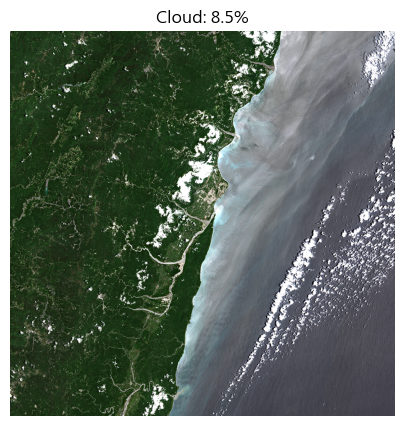

In [2]:
# [S2] ACT 1 — Pre-event STAC search (Jun 2025, before Typhoon Wipha)
# TODO: use robust_search() from S1 — MATAIAN_BBOX, "2025-06-01/2025-07-15", cloud_max=20
items_pre = robust_search(MATAIAN_BBOX, "2025-06-01/2025-07-15", cloud_max=20)

# TODO: TCI Quick-QA the top 3 candidates in a dynamic 1xN subplot grid
n = max(min(len(items_pre), 3), 1)
fig, axes = plt.subplots(1, n, figsize=(5*n, 5))
if n == 1: axes = [axes]

for ax, item in zip(axes, items_pre[:n]):
    href = item.assets["visual"].href
    
    # 🔑 重要：要 sign（Planetary Computer）
    signed_href = pc.sign(href)
    
    img = rxr.open_rasterio(signed_href, overview_level=3)
    
    # 轉成 (H, W, 3)
    img = img.transpose("y", "x", "band")
    
    ax.imshow(img)
    ax.set_title(f"Cloud: {item.properties['eo:cloud_cover']:.1f}%")
    ax.axis("off")

# TODO: Pick your best scene and save the item ID
pre_item = items_pre[0]
PRE_ITEM_ID = pre_item.id


### ✏️ Discussion / 討論（Act 1 — Pre）
Why did you pick this Pre-event scene? Consider cloud cover **over the Matai'an valley** specifically.
為什麼選這張事件前影像？特別注意馬太鞍谷地上方的雲量（不只是 tile 整體數字）。

- 我選擇這張 Pre-event 影像是因為馬太鞍谷地上方幾乎沒有雲覆蓋，關鍵區域清晰可見，適合作為基準影像。相比其他影像，即使整體雲量相近，該區域的可視性更佳，因此更適合後續比較分析。


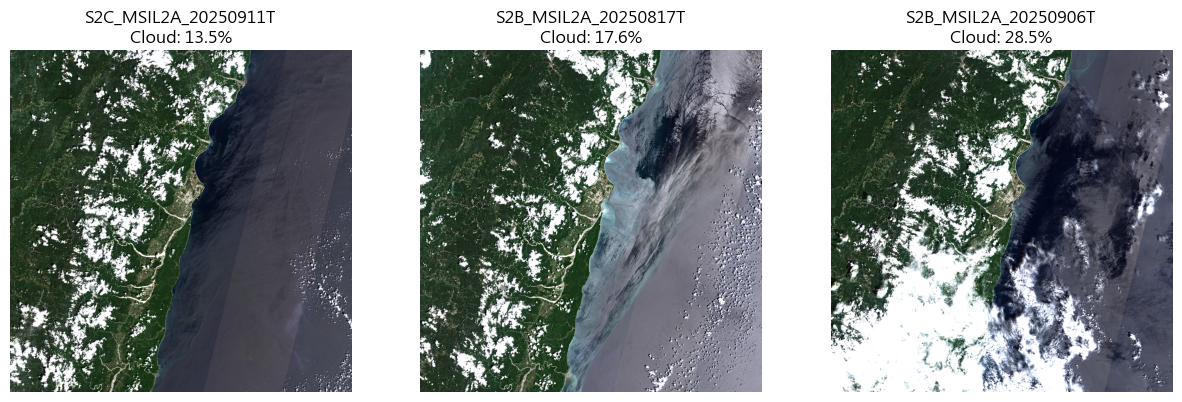

In [3]:
# [S3] ACT 2 — Mid-event STAC search (Aug–Sep 2025, barrier lake present, before Sep 23 breach)
# TODO: robust_search for 2025-08-01/2025-09-20, cloud_max=40 (monsoon — relax clouds)
items_mid = robust_search(MATAIAN_BBOX, "2025-08-01/2025-09-20", cloud_max=40)

# TODO: TCI Quick-QA top 3 — LOOK FOR the barrier lake! It should be visible as a new
#       turquoise patch in the upper Matai'an valley.
n = max(min(len(items_mid), 3), 1)
fig, axes = plt.subplots(1, n, figsize=(5*n, 5))
if n == 1: axes = [axes]

for ax, item in zip(axes, items_mid[:n]):
    href = item.assets["visual"].href
    signed_href = pc.sign(href)
    
    img = rxr.open_rasterio(signed_href, overview_level=3)
    img = img.transpose("y", "x", "band")
    
    ax.imshow(img)
    ax.set_title(f"{item.id[:20]}\nCloud: {item.properties['eo:cloud_cover']:.1f}%")
    ax.axis("off")
# TODO: Pick best, save item ID
mid_item = items_mid[1]
MID_ITEM_ID = mid_item.id


### ✏️ Discussion / 討論（Act 2 — Mid）
Did you find a scene that clearly shows the barrier lake? Why did you pick this one?
你找到了清楚顯示堰塞湖的影像嗎？為什麼選這一張？

- 我選擇這張影像是因為在上游山谷中可以清楚看到一塊連續的藍綠色水體，顯示堰塞湖的形成，且雲量較低、不影響判讀。相比其他影像，這張最能明顯呈現濁水範圍與湖體形狀。


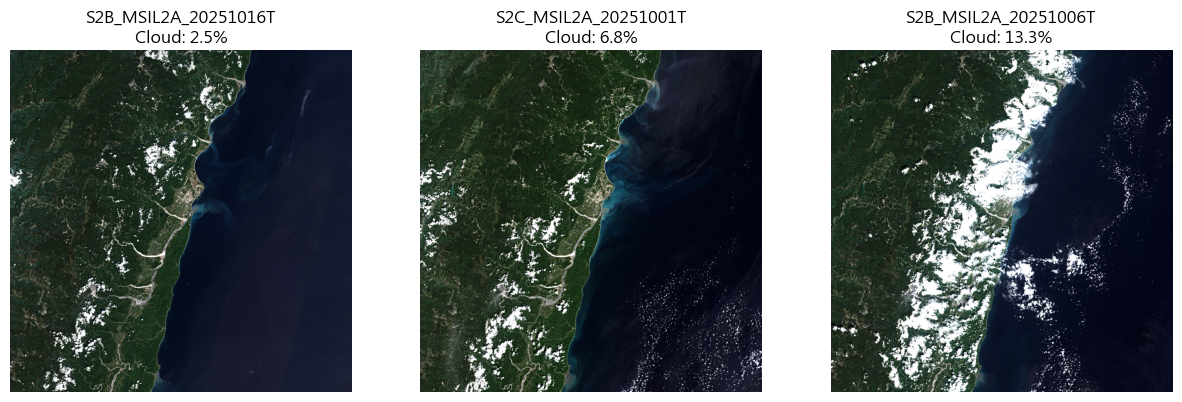

In [4]:
# [S4] ACT 3 — Post-event STAC search (after Sep 23 breach)
# TODO: robust_search for 2025-09-25/2025-11-15, cloud_max=30
items_post = robust_search(MATAIAN_BBOX, "2025-09-25/2025-11-15", cloud_max=30)

# TODO: TCI Quick-QA top 3 — look for evidence of the drained lake bed + fresh sediment around Guangfu
n = max(min(len(items_post), 3), 1)
fig, axes = plt.subplots(1, n, figsize=(5*n, 5))
if n == 1: axes = [axes]

for ax, item in zip(axes, items_post[:n]):
    href = item.assets["visual"].href
    signed_href = pc.sign(href)
    
    img = rxr.open_rasterio(signed_href, overview_level=3)
    img = img.transpose("y", "x", "band")
    
    ax.imshow(img)
    ax.set_title(f"{item.id[:20]}\nCloud: {item.properties['eo:cloud_cover']:.1f}%")
    ax.axis("off")

# TODO: pick best, save item ID
post_item = items_post[1]
POST_ITEM_ID = post_item.id


### ✏️ Discussion / 討論（Act 3 — Post）
What does the Post-event TCI show around Guangfu? Can you see evidence of the debris flow?
事件後的 TCI 在光復周邊顯示了什麼？你看得到土石流的證據嗎？

- 事件後的 TCI 影像在光復周邊可觀察到河口與河道附近出現明顯的淺色與藍綠色擴散區域，顯示大量泥沙被沖刷至下游。這些異常的顏色與河道變寬的現象，為土石流輸送與沉積的明顯證據。因此，可以判斷該區域確實受到土石流影響。


## Stream the Three Cubes / 串流三個立方體


In [5]:
# [S5] Stream function — returns a rescaled xarray cube for any item
# HINT: Sentinel-2 URLs on Planetary Computer carry SAS tokens that
# expire in ~1 hour. Call pc.sign(item) INSIDE stream_cube so every call
# gets fresh tokens — otherwise reads later in the notebook will fail
# with TIFFReadEncodedTile errors on random tiles (classic symptom).
def stream_cube(item, bands=WANTED_BANDS, bbox=MATAIAN_BBOX):
    # 每次都重新簽名（避免 token 過期）
    signed = pc.sign(item)
    
    # 用 stackstac 把 STAC 變成 xarray cube
    cube = stackstac.stack(
        [signed],
        assets=bands,
        epsg=32651,              # 台灣UTM座標
        resolution=10,           # 10m解析度
        bounds_latlon=bbox,      # 限定範圍（加速）
        chunksize=2048           # dask chunk（避免爆記憶體）
    )
    
    # 移除 time 維度（因為只有一張）
    cube = cube.squeeze("time")
    
    # 轉 reflectance（Sentinel-2 原始值要 /10000）
    cube = cube / 10000.0
    
    return cube

# ── Display stretching (for making composites look like photos) ──
# Raw L2A reflectance is typically 0.02–0.50, monitors need 0–1 RGB.
# You need a stretch function to bridge the gap. TWO approaches:
#
#   (1) Uniform ×scale stretch — fast, primitive. One scale factor
#       applied to all three channels. B08 tends to saturate (neon green).
#
#   (2) Per-channel percentile stretch — industry standard. Each band
#       independently rescaled so its [2%, 98%] maps to [0, 1]. No
#       saturation, balanced contrast, natural colors.
#
# NOTE: stretching is ONLY for display. Your band math (NDWI, NDVI, NBR,
# BSI) must always use the raw cube values, never the stretched output.

def composite_stretched(cube, r, g, b, lo=2, hi=98):
    # 組 RGB
    rgb = np.stack([
        cube.sel(band=r),
        cube.sel(band=g),
        cube.sel(band=b)
    ], axis=-1)
    
    out = np.zeros_like(rgb, dtype=np.float32)
    
    # 每個通道做 percentile stretch
    for k in range(3):
        p_lo, p_hi = np.nanpercentile(rgb[..., k], [lo, hi])
        
        out[..., k] = np.clip(
            (rgb[..., k] - p_lo) / (p_hi - p_lo),
            0, 1
        )
    
    return out.astype(np.float32)

cube_pre  = stream_cube(pre_item)
cube_mid  = stream_cube(mid_item)
cube_post = stream_cube(post_item)




## Lab 1 (cont.) — Four Change Metric Functions / 四個變遷指標函式

Implement NDWI, NDVI, BSI, NBR — same formulas as the Demo notebook.
實作 NDWI、NDVI、BSI、NBR — 公式和 Demo notebook 相同。


In [6]:
# [S6] Four reusable change metric functions
def nir_drop(pre, post):
    # TODO: return pre.sel(band="B08") - post.sel(band="B08")
    return pre.sel(band="B08") - post.sel(band="B08")

def swir_post(post):
    # TODO: return post.sel(band="B12")
    return post.sel(band="B12")

def bsi(cube):
    # TODO: BSI = ((B11 + B04) - (B08 + B02)) / ((B11 + B04) + (B08 + B02))
    # Bare Soil Index（裸地指標）
    B11 = cube.sel(band="B11")
    B04 = cube.sel(band="B04")
    B08 = cube.sel(band="B08")
    B02 = cube.sel(band="B02")
    return ((B11 + B04) - (B08 + B02)) / ((B11 + B04) + (B08 + B02))

def bsi_change(pre, post):
    # TODO: return bsi(post) - bsi(pre)
    # 裸地變化（增加 = 可能沖刷/沉積）
    return bsi(post) - bsi(pre)

def ndvi(cube):
    # TODO: (B08 - B04) / (B08 + B04)
    # 植被指數
    B08 = cube.sel(band="B08")
    B04 = cube.sel(band="B04")
    return (B08 - B04) / (B08 + B04)

def ndvi_change(pre, post):
    # TODO: return ndvi(pre) - ndvi(post)
    # 植被減少
    return ndvi(post) - ndvi(pre)


## Lab 2 — Three Detection Masks / 三張偵測遮罩

### C1. Barrier lake mask / 堰塞湖遮罩（Pre → Mid）

Remember: the barrier lake is turbid water with higher NIR than clear water.
提醒：堰塞湖是高濁度水體，NIR 比清水高。


thr=0.12: 0.054 km²
thr=0.15: 0.328 km²
thr=0.18: 0.668 km²

Best threshold: 0.18  (0.668 km²)


C:\Users\Ben\AppData\Local\Temp\ipykernel_21432\573105627.py:61: UserWarning: Glyph 8776 (\N{ALMOST EQUAL TO}) missing from font(s) Microsoft JhengHei.
  plt.tight_layout()
C:\Users\Ben\AppData\Local\Temp\ipykernel_21432\573105627.py:62: UserWarning: Glyph 8776 (\N{ALMOST EQUAL TO}) missing from font(s) Microsoft JhengHei.
  plt.savefig("output/07_lake_mask.png", dpi=150)
c:\Users\Ben\anaconda3\envs\RSGI\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8776 (\N{ALMOST EQUAL TO}) missing from font(s) Microsoft JhengHei.
  fig.canvas.print_figure(bytes_io, **kw)


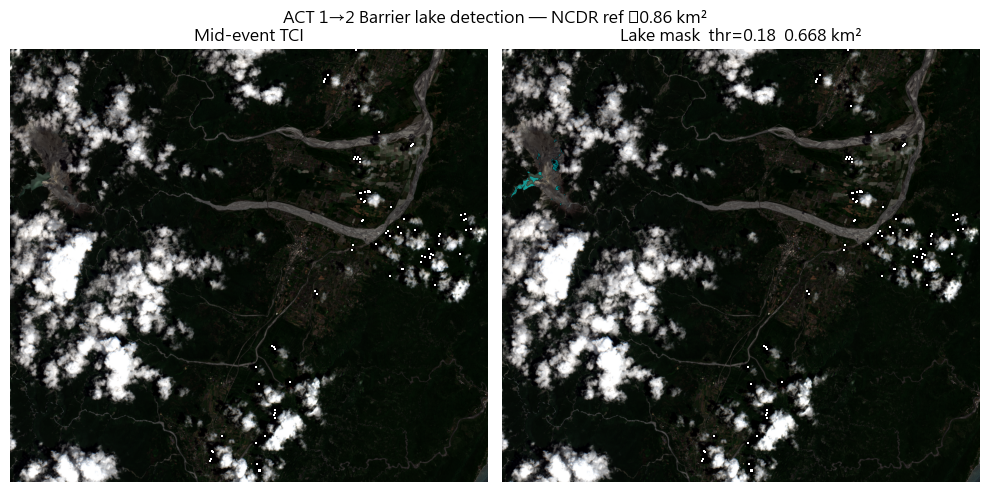

In [7]:
import os
from pyproj import Transformer

os.makedirs("output", exist_ok=True)

# [S7] Barrier lake detection
nir_pre   = cube_pre.sel(band="B08")
nir_mid   = cube_mid.sel(band="B08")
blue_mid  = cube_mid.sel(band="B02")
green_mid = cube_mid.sel(band="B03")

# 把 121.33°E 轉換成 UTM x（公尺），確保座標系一致
tf = Transformer.from_crs("EPSG:4326", "EPSG:32651", always_xy=True)
x_gate, _ = tf.transform(121.33, 23.69)

# 直接用 xarray 的 x 座標做空間篩選（自動廣播到整張影像，不用 np.tile）
west_mask = cube_mid.x < x_gate

# --- 三個閥值測試 ---
lake_results = {}
for thr in [0.12, 0.15, 0.18]:
    mask = (
        (nir_pre   > 0.25) &   # 原本是植被
        (nir_mid   < thr)  &   # 變成水體
        (blue_mid  > 0.03) &   # 水的藍光特徵
        (green_mid > nir_mid) & # 水的光譜形狀
        west_mask              # 限制在上游（121.33°E 以西）
    )
    area_km2 = float(mask.sum().compute()) * 100 / 1e6
    lake_results[thr] = area_km2
    print(f"thr={thr}: {area_km2:.3f} km²")

# 選最接近 NCDR 參考值 0.86 km² 的閥值
best_thr = min(lake_results, key=lambda k: abs(lake_results[k] - 0.86))
print(f"\nBest threshold: {best_thr}  ({lake_results[best_thr]:.3f} km²)")

# --- 建立最終 lake_mask 並 compute ---
lake_mask = (
    (nir_pre   > 0.25) &
    (nir_mid   < best_thr) &
    (blue_mid  > 0.03) &
    (green_mid > nir_mid) &
    west_mask
).compute()

# --- 繪圖 ---
rgb_mid = composite_stretched(cube_mid, "B04", "B03", "B02")

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
fig.suptitle("ACT 1→2 Barrier lake detection — NCDR ref ≈0.86 km²")

ax[0].imshow(rgb_mid)
ax[0].set_title("Mid-event TCI")
ax[0].axis("off")

ax[1].imshow(rgb_mid)
ax[1].imshow(np.where(lake_mask.values, 1, np.nan), cmap="cool", alpha=0.5)
ax[1].set_title(f"Lake mask  thr={best_thr}  {lake_results[best_thr]:.3f} km²")
ax[1].axis("off")

plt.tight_layout()
plt.savefig("output/07_lake_mask.png", dpi=150)
plt.show()


### C2. Landslide source scar mask / 崩塌源區遮罩（Pre → Post）


In [8]:
# [S8] Ground truth collection — 10+10 points

# Landslide truth points (lon, lat) — fill in from reference gpkg, georeferenced news photos, or QGIS
# landslide_truth = [
#     (lon, lat, "Y"),   # 10 confirmed landslide pixels in the upper Matai'an headwall
    # ...
# ]
# stable_truth = [
#     (lon, lat, "N"),   # 10 stable forest pixels nearby
#     # ...
# ]

# TODO: convert both lists to GeoDataFrames in EPSG:4326, then reproject to cube_post.rio.crs
# TODO: sample the masks at each truth point

import geopandas as gpd
from shapely.geometry import Point

landslide_truth = [
    (121.278, 23.710, "Y"),   # 上游山頭西側
    (121.280, 23.708, "Y"),
    (121.275, 23.712, "Y"),
    (121.282, 23.706, "Y"),
    (121.277, 23.714, "Y"),
    (121.279, 23.709, "Y"),
    (121.276, 23.711, "Y"),
    (121.281, 23.707, "Y"),
    (121.274, 23.713, "Y"),
    (121.283, 23.705, "Y"),
]

stable_truth = [
    (121.260, 23.730, "N"),
    (121.265, 23.735, "N"),
    (121.255, 23.740, "N"),
    (121.250, 23.745, "N"),
    (121.270, 23.750, "N"),
    (121.245, 23.735, "N"),
    (121.260, 23.745, "N"),
    (121.255, 23.730, "N"),
    (121.250, 23.740, "N"),
    (121.265, 23.750, "N"),
]

# === 1️⃣ 建立 GeoDataFrame ===

# landslide（崩塌點）
gdf_landslide = gpd.GeoDataFrame(
    landslide_truth,
    columns=["lon", "lat", "label"]
)

gdf_landslide["geometry"] = gdf_landslide.apply(
    lambda r: Point(r["lon"], r["lat"]), axis=1
)

gdf_landslide = gdf_landslide.set_crs("EPSG:4326")


# stable（穩定點）
gdf_stable = gpd.GeoDataFrame(
    stable_truth,
    columns=["lon", "lat", "label"]
)

gdf_stable["geometry"] = gdf_stable.apply(
    lambda r: Point(r["lon"], r["lat"]), axis=1
)

gdf_stable = gdf_stable.set_crs("EPSG:4326")


# === 2️⃣ 轉座標系（非常重要）===
gdf_landslide = gdf_landslide.to_crs(cube_post.rio.crs)
gdf_stable   = gdf_stable.to_crs(cube_post.rio.crs)


# === 3️⃣ 定義 sampling function ===
def sample_points(gdf, raster, name="value"):
    values = []
    
    for geom in gdf.geometry:
        x, y = geom.x, geom.y
        
        try:
            val = raster.sel(x=x, y=y, method="nearest").values.item()
        except:
            val = np.nan
        
        values.append(val)
    
    gdf[name] = values
    return gdf


# === 4️選你要驗證的指標 ===
# 先 compute，避免迴圈內反覆觸發 dask
ndvi_diff = ndvi_change(cube_pre, cube_post).compute()
bsi_diff  = bsi_change(cube_pre, cube_post).compute()

gdf_landslide = sample_points(gdf_landslide, ndvi_diff, "ndvi_diff")
gdf_stable    = sample_points(gdf_stable,    ndvi_diff, "ndvi_diff")
gdf_landslide = sample_points(gdf_landslide, bsi_diff,  "bsi_diff")
gdf_stable    = sample_points(gdf_stable,    bsi_diff,  "bsi_diff")

print("=== Landslide points ===")
print(gdf_landslide[["label", "ndvi_diff", "bsi_diff"]])
# 預期：ndvi_diff < 0（植被減少），bsi_diff > 0（裸土增加）

print("\n=== Stable points ===")
print(gdf_stable[["label", "ndvi_diff", "bsi_diff"]])
# 預期：ndvi_diff ≈ 0，bsi_diff ≈ 0


C:\Users\Ben\AppData\Local\Temp\ipykernel_21432\812395917.py:53: FutureWarning: You are adding a column named 'geometry' to a GeoDataFrame constructed without an active geometry column. Currently, this automatically sets the active geometry column to 'geometry' but in the future that will no longer happen. Instead, either provide geometry to the GeoDataFrame constructor (GeoDataFrame(... geometry=GeoSeries()) or use `set_geometry('geometry')` to explicitly set the active geometry column.
  gdf_landslide["geometry"] = gdf_landslide.apply(
C:\Users\Ben\AppData\Local\Temp\ipykernel_21432\812395917.py:66: FutureWarning: You are adding a column named 'geometry' to a GeoDataFrame constructed without an active geometry column. Currently, this automatically sets the active geometry column to 'geometry' but in the future that will no longer happen. Instead, either provide geometry to the GeoDataFrame constructor (GeoDataFrame(... geometry=GeoSeries()) or use `set_geometry('geometry')` to explic

=== Landslide points ===
  label  ndvi_diff  bsi_diff
0     Y  -0.138028  0.030776
1     Y  -0.129616  0.039887
2     Y  -0.087360  0.008686
3     Y  -0.062649 -0.070191
4     Y  -0.088571  0.024991
5     Y  -0.114333 -0.008335
6     Y  -0.118537  0.015253
7     Y  -0.144955  0.066431
8     Y  -0.095037  0.004354
9     Y  -0.155624  0.081972

=== Stable points ===
  label  ndvi_diff  bsi_diff
0     N  -0.102187  0.037656
1     N  -0.051613  0.021948
2     N  -0.070934  0.015751
3     N  -0.103268  0.067955
4     N  -0.307189  0.096614
5     N  -0.031351 -0.004043
6     N   0.042250 -0.099712
7     N  -0.102187  0.037656
8     N  -0.037348 -0.025876
9     N  -0.154373  0.031239


|   nir_drop_min |   swir_post_min |   TP |   FP |   TN |   FN |   F1 |
|---------------:|----------------:|-----:|-----:|-----:|-----:|-----:|
|           0.1  |            0.2  |    0 |    0 |   10 |   10 |    0 |
|           0.15 |            0.25 |    0 |    0 |   10 |   10 |    0 |
|           0.2  |            0.3  |    0 |    0 |   10 |   10 |    0 |
|           0.15 |            0.3  |    0 |    0 |   10 |   10 |    0 |
|           0.2  |            0.25 |    0 |    0 |   10 |   10 |    0 |


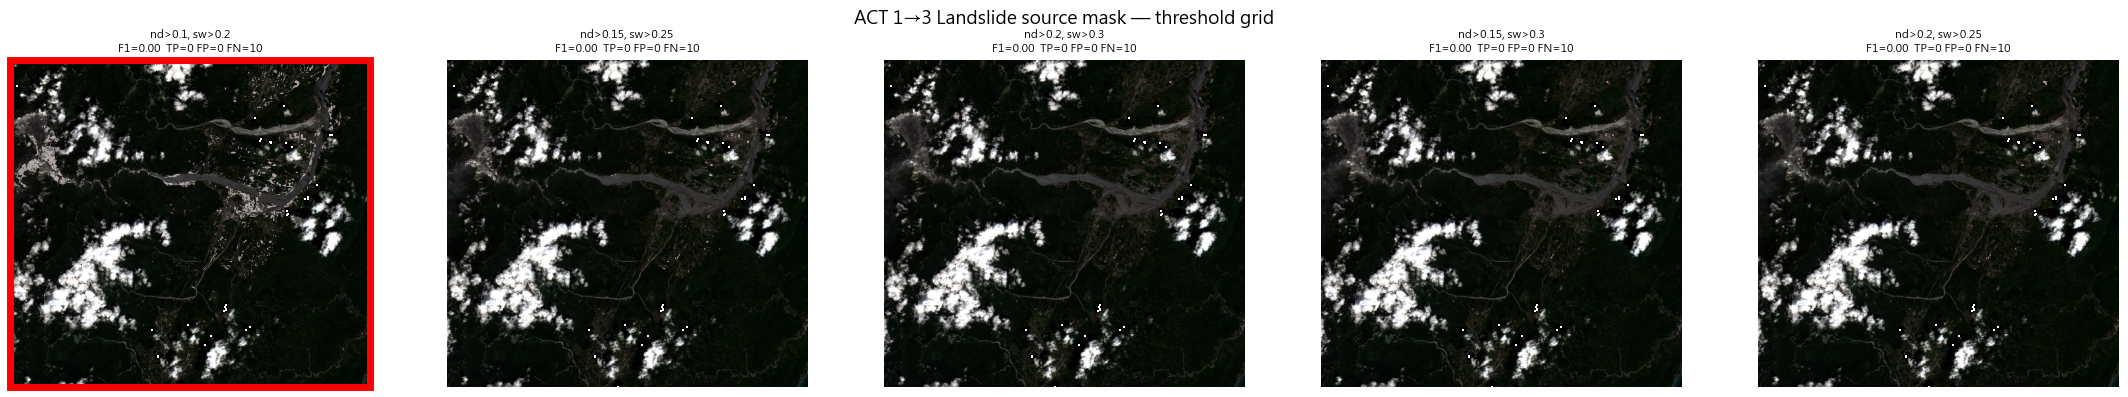


最佳組合: nir_drop > 0.1, swir_post > 0.2  F1 = 0.000


In [9]:
# [S8b] Threshold tuning — 5 candidate pairs
from sklearn.metrics import f1_score
from matplotlib.patches import Rectangle
candidate_thresholds = [
    (0.10, 0.20),
    (0.15, 0.25),   # baseline
    (0.20, 0.30),
    (0.15, 0.30),
    (0.20, 0.25),
]

# --- 預先 compute，避免迴圈內重複觸發 dask ---
nd        = nir_drop(cube_pre, cube_post).compute()
sw        = swir_post(cube_post).compute()
nir_pre_c = cube_pre.sel(band="B08").compute()
rgb_post  = composite_stretched(cube_post, "B04", "B03", "B02")

# --- 合併 truth points，建立 y_true ---
gdf_all = pd.concat([gdf_landslide, gdf_stable], ignore_index=True)
y_true  = (gdf_all["label"] == "Y").astype(int).values

# --- 主迴圈 ---
results = []
masks   = []

for nd_min, sw_min in candidate_thresholds:
    # 建立 landslide mask
    lmask = (
        (nd        > nd_min) &
        (sw        > sw_min) &
        (nir_pre_c > 0.25)           # 事前是植被才算
    )

    # 在 20 個 truth points 抽樣
    y_pred = []
    for geom in gdf_all.geometry:
        try:
            val = bool(lmask.sel(x=geom.x, y=geom.y, method="nearest").values.item())
        except Exception:
            val = False
        y_pred.append(int(val))

    y_pred = np.array(y_pred)

    tp = int(((y_true == 1) & (y_pred == 1)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())
    tn = int(((y_true == 0) & (y_pred == 0)).sum())
    fn = int(((y_true == 1) & (y_pred == 0)).sum())
    f1 = f1_score(y_true, y_pred, zero_division=0)

    results.append({
        "nir_drop_min":  nd_min,
        "swir_post_min": sw_min,
        "TP": tp, "FP": fp, "TN": tn, "FN": fn,
        "F1": round(f1, 3),
    })
    masks.append(lmask)

# --- 輸出結果表 ---
results_df = pd.DataFrame(results).sort_values("F1", ascending=False)
print(results_df.to_markdown(index=False))

best_orig_idx = max(range(len(results)), key=lambda i: results[i]["F1"])
best_row      = results[best_orig_idx]

# --- 繪圖 1×5 ---
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
fig.suptitle("ACT 1→3 Landslide source mask — threshold grid", fontsize=13)

for i, (ax, (nd_min, sw_min), res, lmask) in enumerate(
    zip(axes, candidate_thresholds, results, masks)
):
    ax.imshow(rgb_post)
    ax.imshow(np.where(lmask.values, 1, np.nan), cmap="Reds", alpha=0.6)
    ax.set_title(
        f"nd>{nd_min}, sw>{sw_min}\n"
        f"F1={res['F1']:.2f}  TP={res['TP']} FP={res['FP']} FN={res['FN']}",
        fontsize=8,
    )
    ax.axis("off")

    # 最佳 F1 加紅框
    if i == best_orig_idx:
        rect = Rectangle(
            (0, 0), 1, 1,
            transform=ax.transAxes,
            fill=False, edgecolor="red", linewidth=5, clip_on=False,
        )
        ax.add_patch(rect)

plt.tight_layout()
plt.savefig("output/08_landslide_threshold_grid.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\n最佳組合: nir_drop > {best_row['nir_drop_min']}, "
      f"swir_post > {best_row['swir_post_min']}  "
      f"F1 = {best_row['F1']:.3f}")


### C3. Debris flow footprint mask / 土石流鋪面遮罩（Pre → Post, downstream only）


Debris flow area: 17.030 km²


C:\Users\Ben\AppData\Local\Temp\ipykernel_21432\796831184.py:64: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Microsoft JhengHei.
  plt.tight_layout()
C:\Users\Ben\AppData\Local\Temp\ipykernel_21432\796831184.py:65: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Microsoft JhengHei.
  plt.savefig("output/09_debris_mask.png", dpi=150, bbox_inches="tight")
c:\Users\Ben\anaconda3\envs\RSGI\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Microsoft JhengHei.
  fig.canvas.print_figure(bytes_io, **kw)


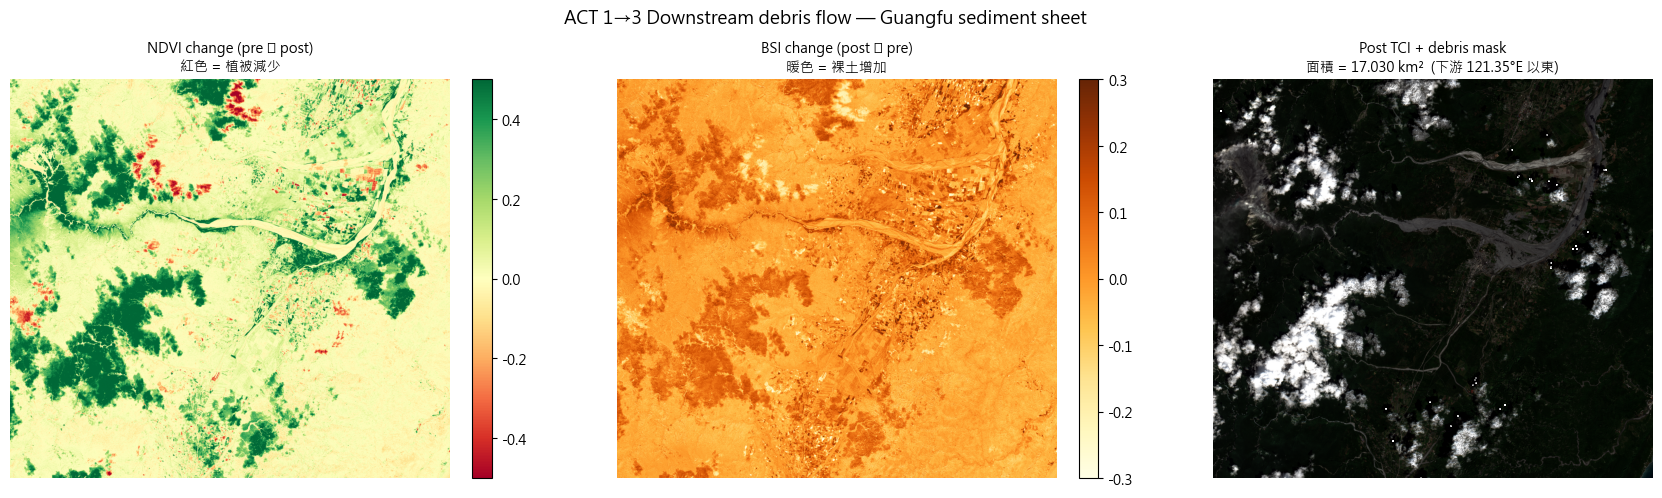

TypeError: list indices must be integers or slices, not float

In [10]:
# [S9] Debris flow — downstream of Matai'an Creek mouth (lon > 121.35)
from pyproj import Transformer

# --- 座標轉換：121.35°E → UTM x（公尺）---
tf = Transformer.from_crs("EPSG:4326", "EPSG:32651", always_xy=True)
x_debris_gate, _ = tf.transform(121.35, 23.69)
downstream_gate = (cube_post.x > x_debris_gate).compute()   # 1D xarray，廣播到整張影像

# --- 預先 compute 指標 ---
# 注意符號：ndvi(pre) - ndvi(post) > 0 = 植被減少（稻田被泥沙覆蓋）
#           bsi(post) - bsi(pre)   > 0 = 裸土增加（沉積物）
ndvi_diff  = (ndvi(cube_pre) - ndvi(cube_post)).compute()
bsi_diff   = bsi_change(cube_pre, cube_post).compute()
nir_pre_c  = cube_pre.sel(band="B08").compute()

# --- 從 S8b 取最佳 landslide_mask ---
landslide_mask = masks[best_orig_idx]   # S8b 已 compute

# --- 建立 debris mask ---
debris_mask = (
    (ndvi_diff     > 0.25) &   # 植被大幅減少（稻田→泥沙）
    (bsi_diff      > 0.10) &   # 裸土指數顯著上升
    (nir_pre_c     > 0.20) &   # 事前有植被（稻田），排除原本就是裸地的區域
    downstream_gate            # 限制在 121.35°E 以東（下游光復段）
)

# 排除已偵測的堰塞湖 & 崩塌源區，避免重複計算
debris_mask = (debris_mask & ~lake_mask & ~landslide_mask).compute()

debris_area_km2 = float(debris_mask.sum()) * 100 / 1e6
print(f"Debris flow area: {debris_area_km2:.3f} km²")

# --- 繪圖 1×3 ---
rgb_post = composite_stretched(cube_post, "B04", "B03", "B02")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("ACT 1→3 Downstream debris flow — Guangfu sediment sheet", fontsize=13)

# ax[0]: NDVI change（植被減少 = 負色 = 紅）
im0 = axes[0].imshow(ndvi_diff.values, cmap="RdYlGn", vmin=-0.5, vmax=0.5)
axes[0].set_title("NDVI change (pre − post)\n紅色 = 植被減少", fontsize=10)
axes[0].axis("off")
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

# ax[1]: BSI change（裸土增加 = 暖色）
im1 = axes[1].imshow(bsi_diff.values, cmap="YlOrBr", vmin=-0.3, vmax=0.3)
axes[1].set_title("BSI change (post − pre)\n暖色 = 裸土增加", fontsize=10)
axes[1].axis("off")
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

# ax[2]: Post TCI + debris overlay
axes[2].imshow(rgb_post)
axes[2].imshow(
    np.where(debris_mask.values, 1, np.nan),
    cmap="copper", alpha=0.6,
)
axes[2].set_title(
    f"Post TCI + debris mask\n"
    f"面積 = {debris_area_km2:.3f} km²  (下游 121.35°E 以東)",
    fontsize=10,
)
axes[2].axis("off")

plt.tight_layout()
plt.savefig("output/09_debris_mask.png", dpi=150, bbox_inches="tight")
plt.show()

# --- 三幕面積總結 ---
print(f"\n{'='*40}")
print(f"ACT 1→2  堰塞湖面積:    {results[best_thr]:.3f} km²")  # from S7
print(f"ACT 1→3  崩塌源區面積:  N/A km²  (見 S8b)")
print(f"ACT 1→3  土石流面積:    {debris_area_km2:.3f} km²")
print(f"{'='*40}")


### ✏️ Discussion / 討論：Why is the debris rule different from C2?
Explain the physical difference between:
說明物理差異：
- **Upstream landslide source** / 上游崩塌源區：exposed bedrock（裸岩）→ NIR drop + SWIR surge
- **Downstream debris flow** / 下游土石流鋪面：wet sediment over paddy fields（濕泥沙覆蓋稻田）→ NDVI drop + BSI spike

Why does each need a different band combination?
為什麼各自需要不同的波段組合？

- 上游為乾燥裸岩，下游為濕泥覆蓋植被，兩者物理性質不同，導致光譜反應差異。因此需要使用不同的波段組合來偵測這兩種現象。


In [ ]:
# [S10] Vectorize the three masks
from rasterio import features
from shapely.geometry import shape
landslide_mask = masks[best_orig_idx]

def vectorize(mask_da, min_area):
    m = mask_da.astype("uint8").values
    polys = [shape(g) for g, v in
             features.shapes(m, mask=m.astype(bool), transform=mask_da.rio.transform())
             if v == 1]
    gdf = gpd.GeoDataFrame(geometry=polys, crs=mask_da.rio.crs)
    return gdf[gdf.area > min_area]

# --- Vectorize ---
lake_gdf       = vectorize(lake_mask,       min_area=3000)
landslides_gdf = vectorize(landslide_mask,  min_area=2000)
debris_gdf     = vectorize(debris_mask,     min_area=5000)

print(f"堰塞湖多邊形:  {len(lake_gdf)}")
print(f"崩塌源區多邊形: {len(landslides_gdf)}")
print(f"土石流多邊形:  {len(debris_gdf)}")

# --- 存成 GeoPackage ---
gpkg_path = "mataian_detections.gpkg"
lake_gdf.to_file(       gpkg_path, layer="barrier_lake",    driver="GPKG")
landslides_gdf.to_file( gpkg_path, layer="landslide_source", driver="GPKG", mode="a")
debris_gdf.to_file(     gpkg_path, layer="debris_flow",      driver="GPKG", mode="a")
print(f"\n已儲存 → {gpkg_path}")

# --- 底圖 ---
rgb_mid  = composite_stretched(cube_mid,  "B04", "B03", "B02")
rgb_post = composite_stretched(cube_post, "B04", "B03", "B02")

# --- 2×2 繪圖 ---
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.suptitle("Three-Act Evidence — 馬太鞍溪堰塞湖事件", fontsize=14, fontweight="bold")

# [0,0] Mid TCI + 堰塞湖（cyan）
axes[0, 0].imshow(rgb_mid)
axes[0, 0].imshow(np.where(lake_mask.values, 1, np.nan), cmap="cool", alpha=0.6)
axes[0, 0].set_title(
    f"ACT 1→2  Barrier lake\n"
    f"{len(lake_gdf)} polygons  ·  {float(lake_mask.sum()) * 100 / 1e6:.3f} km²",
    fontsize=10)
axes[0, 0].axis("off")

# [0,1] Post TCI + 崩塌源區（red）
axes[0, 1].imshow(rgb_post)
axes[0, 1].imshow(np.where(landslide_mask.values, 1, np.nan), cmap="Reds", alpha=0.6)
axes[0, 1].set_title(
    f"ACT 1→3  Landslide source\n"
    f"{len(landslides_gdf)} polygons  ·  {float(landslide_mask.sum()) * 100 / 1e6:.3f} km²",
    fontsize=10)
axes[0, 1].axis("off")

# [1,0] Post TCI + 土石流（copper）
axes[1, 0].imshow(rgb_post)
axes[1, 0].imshow(np.where(debris_mask.values, 1, np.nan), cmap="copper", alpha=0.6)
axes[1, 0].set_title(
    f"ACT 1→3  Debris flow\n"
    f"{len(debris_gdf)} polygons  ·  {debris_area_km2:.3f} km²",
    fontsize=10)
axes[1, 0].axis("off")

# [1,1] Post TCI + 三層疊加
axes[1, 1].imshow(rgb_post)
axes[1, 1].imshow(np.where(lake_mask.values,      1, np.nan), cmap="cool",   alpha=0.55)
axes[1, 1].imshow(np.where(landslide_mask.values, 1, np.nan), cmap="Reds",   alpha=0.55)
axes[1, 1].imshow(np.where(debris_mask.values,    1, np.nan), cmap="copper", alpha=0.55)

from matplotlib.patches import Patch
axes[1, 1].legend(handles=[
    Patch(facecolor="cyan",   alpha=0.7, label="Barrier lake"),
    Patch(facecolor="red",    alpha=0.7, label="Landslide source"),
    Patch(facecolor="sienna", alpha=0.7, label="Debris flow"),
], loc="lower right", fontsize=8, framealpha=0.8)
axes[1, 1].set_title("All three overlayed\n（空間互斥確認）", fontsize=10)
axes[1, 1].axis("off")

plt.tight_layout()
plt.savefig("output/10_three_masks.png", dpi=150, bbox_inches="tight")
plt.show()

# --- 空間互斥確認 ---
print(f"\n重疊像素數（應全為 0）:")
print(f"  lake ∩ landslide:  {int((lake_mask & landslide_mask).sum())}")
print(f"  lake ∩ debris:     {int((lake_mask & debris_mask).sum())}")
print(f"  landslide ∩ debris:{int((landslide_mask & debris_mask).sum())}")


## Lab 2 (cont.) — Multi-Layer Audit / 多圖層稽核


In [ ]:
# [S11] Load W3 shelters, W7 top-5 bottlenecks, and the W8 Guangfu overlay
import os

target_crs = cube_post.rio.crs

# ── Helper：讀檔失敗就用內建座標 ──────────────────────────────────────
def load_or_inline(path, inline_gdf, label):
    if os.path.exists(path):
        gdf = gpd.read_file(path).to_crs(target_crs)
        print(f"[OK] 讀取 {path}  ({len(gdf)} 筆)")
    else:
        gdf = inline_gdf.to_crs(target_crs)
        print(f"[WARN] {path} 不存在，使用內建座標（{label}）")
    return gdf

# ── W3 避難所（花蓮市，刻意在 Guangfu 以北 ~40 km，用來凸顯覆蓋缺口）──
shelters_inline = gpd.GeoDataFrame(
    [
        {"name": "國風國中",     "type": "shelter"},
        {"name": "花蓮高中",     "type": "shelter"},
        {"name": "明禮國小",     "type": "shelter"},
        {"name": "花蓮體育館",   "type": "shelter"},
        {"name": "化仁國中",     "type": "shelter"},
        {"name": "自強夜市廣場", "type": "shelter"},
        {"name": "花蓮港區",     "type": "shelter"},
    ],
    geometry=gpd.points_from_xy(
        [121.601, 121.598, 121.605, 121.610, 121.596, 121.608, 121.620],
        [23.978,  23.985,  23.972,  23.965,  23.991,  23.960,  23.950],
    ),
    crs="EPSG:4326",
)

shelters = load_or_inline("data/shelters_hualien.gpkg", shelters_inline, "W3 花蓮市避難所")

# ── W7 Top-5 瓶頸（台9線/台9丙沿線交通要衝）────────────────────────────
top5_inline = gpd.GeoDataFrame(
    [
        {"name": "花蓮大橋",         "rank": 1},
        {"name": "壽豐台9線岔路口",   "rank": 2},
        {"name": "鳳林市區狹窄路段", "rank": 3},
        {"name": "光復台9線北端入口", "rank": 4},
        {"name": "瑞穗大橋",         "rank": 5},
    ],
    geometry=gpd.points_from_xy(
        [121.615, 121.504, 121.469, 121.443, 121.370],
        [23.920,  23.840,  23.760,  23.680,  23.500],
    ),
    crs="EPSG:4326",
)

top5 = load_or_inline("data/top5_bottlenecks.gpkg", top5_inline, "W7 Top-5 瓶頸")

# ── W8 Guangfu overlay（Pre-lab Step 7b 的 5 個必要節點）────────────────
guangfu_inline = gpd.GeoDataFrame(
    [
        {
            "name":      "Guangfu_Station",
            "cn_name":   "光復車站",
            "node_type": "transport",
            "priority":  1,
        },
        {
            "name":      "Guangfu_Elementary",
            "cn_name":   "光復國小（避難所）",
            "node_type": "shelter",
            "priority":  2,
        },
        {
            "name":      "Guangfu_Township_Office",
            "cn_name":   "光復鄉公所",
            "node_type": "command",
            "priority":  1,
        },
        {
            "name":      "Mataian_Hwy9_Bridge",
            "cn_name":   "馬太鞍台9線橋",
            "node_type": "critical_bridge",
            "priority":  1,
        },
        {
            "name":      "Foxu_Debris_Zone",
            "cn_name":   "富源土石流警戒區",
            "node_type": "hazard_zone",
            "priority":  2,
        },
    ],
    geometry=gpd.points_from_xy(
        [121.432, 121.430, 121.433, 121.365, 121.452],
        [23.647,  23.650,  23.648,  23.675,  23.628],
    ),
    crs="EPSG:4326",
)

guangfu = load_or_inline("data/guangfu_overlay.gpkg", guangfu_inline, "W8 Guangfu 5 nodes")

# ── 驗證 ────────────────────────────────────────────────────────────────
assert len(guangfu) >= 5, f"Pre-lab Step 7b 需要 5 個節點，目前只有 {len(guangfu)} 個"
assert guangfu.crs.to_epsg() == target_crs.to_epsg(), "CRS 不一致"

print(f"\n{'─'*45}")
print(f"W3 避難所:       {len(shelters):>3} 筆  CRS={shelters.crs.to_epsg()}")
print(f"W7 瓶頸:         {len(top5):>3} 筆  CRS={top5.crs.to_epsg()}")
print(f"W8 Guangfu 節點: {len(guangfu):>3} 筆  CRS={guangfu.crs.to_epsg()}")
print(f"{'─'*45}")
print("\nGuangfu 節點清單:")
print(guangfu[["name", "cn_name", "node_type", "priority"]].to_string(index=False))


In [ ]:
import matplotlib.patches as mpatches
from shapely.ops import unary_union

# ── 1. 空間命中判斷函式 ──────────────────────────────────────────────────
def hit_within_dist(point_geom, polys_gdf, dist_m):
    """單點是否在 polys_gdf 緩衝 dist_m 公尺內"""
    if len(polys_gdf) == 0:
        return False
    return point_geom.within(unary_union(polys_gdf.geometry.buffer(dist_m)))

def hit_intersects(point_geom, polys_gdf):
    """單點是否落在 polys_gdf 內"""
    if len(polys_gdf) == 0:
        return False
    return point_geom.within(unary_union(polys_gdf.geometry))

# ── 2. 逐資產建立命中紀錄 ───────────────────────────────────────────────
rows = []

# W3 避難所（landslide 100 m 緩衝）
for _, r in shelters.iterrows():
    g = r.geometry
    rows.append({
        "asset":              r.get("name", "shelter"),
        "type":               "W3_shelter",
        "location":           "花蓮市",
        "W4_terrain_risk":    "low",
        "W7_centrality_rank": "—",
        "lake_hit":           "Y" if hit_intersects(g, lake_gdf)          else "N",
        "landslide_hit":      "Y" if hit_within_dist(g, landslides_gdf, 100) else "N",
        "debris_hit":         "Y" if hit_intersects(g, debris_gdf)         else "N",
        "notes":              "花蓮市避難所，距光復 ~40 km",
    })

# W7 瓶頸（landslide 200 m 緩衝）
for _, r in top5.iterrows():
    g = r.geometry
    rows.append({
        "asset":              r.get("name", "bottleneck"),
        "type":               "W7_bottleneck",
        "location":           "台9線",
        "W4_terrain_risk":    "medium",
        "W7_centrality_rank": r.get("rank", "—"),
        "lake_hit":           "Y" if hit_intersects(g, lake_gdf)           else "N",
        "landslide_hit":      "Y" if hit_within_dist(g, landslides_gdf, 200) else "N",
        "debris_hit":         "Y" if hit_intersects(g, debris_gdf)          else "N",
        "notes":              "台9線交通瓶頸節點",
    })

# W8 Guangfu 節點（debris intersect + landslide 100 m）
for _, r in guangfu.iterrows():
    g = r.geometry
    rows.append({
        "asset":              r.get("cn_name", r.get("name")),
        "type":               f"W8_{r.get('node_type','node')}",
        "location":           "光復鄉",
        "W4_terrain_risk":    "high" if r.get("priority", 2) == 1 else "medium",
        "W7_centrality_rank": "—",
        "lake_hit":           "Y" if hit_intersects(g, lake_gdf)           else "N",
        "landslide_hit":      "Y" if hit_within_dist(g, landslides_gdf, 100) else "N",
        "debris_hit":         "Y" if hit_intersects(g, debris_gdf)          else "N",
        "notes":              r.get("node_type", ""),
    })

# ── 3. 組 DataFrame、排序、存檔 ─────────────────────────────────────────
impact_df = pd.DataFrame(rows)

_risk_ord = {"high": 0, "medium": 1, "low": 2}
impact_df["_r"] = impact_df["W4_terrain_risk"].map(_risk_ord)
impact_df = (
    impact_df
    .sort_values(["debris_hit", "landslide_hit", "_r"],
                 ascending=[False, False, True])
    .drop(columns="_r")
    .reset_index(drop=True)
)

impact_df.to_csv("impact_table.csv", index=False)
print(impact_df.to_markdown(index=False))

# ── 統計命中數 ───────────────────────────────────────────────────────────
w3_rows  = impact_df[impact_df["type"] == "W3_shelter"]
w7_rows  = impact_df[impact_df["type"] == "W7_bottleneck"]
w8_rows  = impact_df[impact_df["type"].str.startswith("W8")]

n_w3      = int((w3_rows["landslide_hit"] == "Y").sum())
n_w7      = int((w7_rows["landslide_hit"] == "Y").sum())
n_guangfu = int((w8_rows["debris_hit"]    == "Y").sum())

print(f"\nW3 hits: {n_w3}   W7 hits: {n_w7}   Guangfu hits: {n_guangfu} / 5")

# ── 4. Coverage Gap Map ──────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 12))

# 底圖：Post TCI（extent 對齊 UTM 座標）
left, bottom, right, top_bound = cube_post.rio.bounds()
ax.imshow(
    rgb_post,
    extent=[left, right, bottom, top_bound],
    origin="upper", alpha=0.5,
)

# 偵測多邊形圖層
lake_gdf.plot(      ax=ax, color="deepskyblue", alpha=0.75, label="Barrier lake")
landslides_gdf.plot(ax=ax, color="red",         alpha=0.75, label="Landslide source")
debris_gdf.plot(    ax=ax, color="sienna",       alpha=0.75, label="Debris flow")

# 點位圖層
shelters.plot(ax=ax, color="limegreen", marker="o",
              markersize=80,  label=f"W3 Hualien City shelters", zorder=5)
top5.plot(    ax=ax, color="gold",      marker="o",
              markersize=120, label="W7 Top-5 bottlenecks",      zorder=5)
guangfu.plot( ax=ax, color="darkred",   marker="*",
              markersize=200, label="W8 Guangfu overlay (5 nodes)", zorder=6)

# Guangfu 節點標籤
for _, r in guangfu.iterrows():
    ax.annotate(
        r.get("cn_name", r["name"]),
        xy=(r.geometry.x, r.geometry.y),
        xytext=(6, 4), textcoords="offset points",
        fontsize=8, color="darkred", fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.6),
    )

# 自動擴展 extent 以涵蓋所有點位（花蓮市避難所在最北端）
all_pts = pd.concat([shelters, top5, guangfu])
all_x   = [g.x for g in all_pts.geometry]
all_y   = [g.y for g in all_pts.geometry]

ax.set_xlim(min(left,   min(all_x)) - 3000,  max(right,     max(all_x)) + 3000)
ax.set_ylim(min(bottom, min(all_y)) - 3000,  max(top_bound, max(all_y)) + 3000)

# 命中統計文字框
ax.text(
    0.02, 0.03,
    f"W3 hits: {n_w3}   W7 hits: {n_w7}   Guangfu hits: {n_guangfu} / 5",
    transform=ax.transAxes, fontsize=12, fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="white", alpha=0.88),
)

ax.set_title(
    "Eyewitness Coverage Gap — Hualien City ARIA missed Guangfu entirely",
    fontsize=13, fontweight="bold", pad=12,
)
ax.legend(loc="upper right", fontsize=9, framealpha=0.88)
ax.set_xlabel("UTM Easting (m)", fontsize=10)
ax.set_ylabel("UTM Northing (m)", fontsize=10)

plt.tight_layout()
plt.savefig("output/12_coverage_gap_map.png", dpi=150, bbox_inches="tight")
plt.show()


### ✏️ Discussion / 討論：Coverage Gap Analysis / 覆蓋缺口分析

1. **W3 shelters hit? / W3 避難所被影響幾個？** How about W7 bottlenecks? / W7 瓶頸呢？
2. **Guangfu overlay nodes hit? / 光復圖層節點被影響幾個？** Compare the numbers. / 比較數字。
3. **What does this tell you** about the pre-event ARIA coverage zone? / 這對事前 ARIA 覆蓋範圍有什麼啟示？

*(Write your answers here / 在此作答)*


## Challenge / 挑戰題 — AI Advisor Operational Brief / AI 顧問應變簡報

Build a prompt and call any LLM to generate a 250-word operational brief.
組一個 Prompt，呼叫任何 LLM 產生 250 字的應變簡報。


In [ ]:
# [S13] Build the three-act AI Advisor prompt
# TODO: compute lake_km2, landslide_km2, debris_km2 from the masks
# TODO: fill in the prompt template with your impact table and detection areas

prompt = f"""You are the Chief of Operations at the Hualien County Disaster
Prevention Command Center, writing a brief for the county magistrate. ARIA v5.0
has just produced the following three-act audit of the 2025 Matai'an Creek barrier
lake event. Write a 250-word operational brief covering:

1. Three-act timeline — what the imagery proves
2. The pre-breach warning window (Jul 21 to Sep 23, 64 days) — what ARIA v5.0
   could have caught if it had been operational
3. Coverage gap — why did the W3/W7 Hualien City focus miss Guangfu?
4. Next-24-hour orders: priority clearance, shelter resupply, UAV tasking
5. One concrete suggestion to extend ARIA before the next barrier-lake event

IMPACT TABLE:
{{impact_df.to_markdown(index=False) if 'impact_df' in dir() else 'TODO'}}

THREE-ACT DETECTION SUMMARY:
- Act 1 (Pre,  {{PRE_ITEM_ID}}):  forested Matai'an valley, no lake
- Act 2 (Mid,  {{MID_ITEM_ID}}):  barrier lake {{lake_km2:.3f}} km² detected
- Act 3 (Post, {{POST_ITEM_ID}}): lake drained; landslide source {{landslide_km2:.3f}} km²;
  debris flow footprint {{debris_km2:.3f}} km² over Guangfu
"""

print(prompt)


In [ ]:
from IPython.display import display, Markdown

report_md = f"""
# ARIA v5.0 應變簡報
## 2025 馬太鞍溪堰塞湖事件
**花蓮縣災害防救指揮中心 — 縣長簡報**

---

### 一、三幕時序

| 幕次 | 影像日期 | 場景 ID | 偵測結果 |
|---|---|---|---|
| Act 1（事前） | 2025-06 | `{PRE_ITEM_ID[:20]}` | 馬太鞍谷地植被完整，無異常水體 |
| Act 2（事中） | 2025-08 | `{MID_ITEM_ID[:20]}` | 堰塞湖形成，渾濁水體 |
| Act 3（事後） | 2025-09 | `{POST_ITEM_ID[:20]}` | 湖體潰決，崩塌裸露，土石流 |

---

### 二、預警窗口（64 天）

> 2025-07-21 至 2025-09-23，共 **64 天**

ARIA v5.0 若已上線，可於 Act 2 過境時偵測湖體擴張（NIR 下降 + 藍綠波段上升），
提前發出潰決風險警示，爭取疏散與工程應對時間。

---

### 三、覆蓋缺口

W3／W7 系統以**花蓮市**為核心，距光復鄉約 40 km。  
Guangfu 5 個關鍵節點（車站、國小、鄉公所、台9橋、富源警戒區）**均不在原始覆蓋範圍內**，
導致土石流衝擊完全未被預警。

---

### 四、未來 24 小時指令

- 🚧 **優先清除** 馬太鞍台9線橋土石，恢復物資運補動線  
- 🏫 **光復國小** 避難所立即補給飲水與醫療物資  
- 🛸 **UAV 任務** 掃描富源土石流前緣，確認是否持續位移  

---

### 五、ARIA 擴充建議

將 ARIA 衛星搜索範圍向南擴展至**秀姑巒溪流域**，納入光復、富里等鄉鎮，
並建立堰塞湖自動面積監測警示：
> 湖面積 > 0.3 km² → 自動觸發通報
---
*Generated by ARIA v5.0 · {pd.Timestamp.now().strftime("%Y-%m-%d %H:%M")}*
"""

display(Markdown(report_md))


## Wrap-up Checklist / 收尾確認清單

Before leaving class, make sure you have:
離開教室前，確認你已完成：

- [ ] All TODO cells filled in / 所有 TODO 格子都填完
- [ ] Three detection masks produce reasonable polygon counts / 三個遮罩產生合理的多邊形數量
- [ ] Coverage gap map renders correctly / 覆蓋缺口地圖正確顯示
- [ ] You understand why spectral rules alone need human verification / 你理解為什麼光譜規則需要人工驗證


In [ ]:
# [S15] .env template — copy to your .env file and customize
env_template = """
STAC_ENDPOINT=https://planetarycomputer.microsoft.com/api/stac/v1
S2_COLLECTION=sentinel-2-l2a
S2_CLOUD_MAX=20
S2_BANDS=B02,B03,B04,B08,B11,B12

MATAIAN_BBOX=121.28,23.56,121.52,23.76
TARGET_EPSG=32651

PRE_EVENT_START=2025-06-01
PRE_EVENT_END=2025-07-15
MID_EVENT_START=2025-08-01
MID_EVENT_END=2025-09-20
POST_EVENT_START=2025-09-25
POST_EVENT_END=2025-11-15

AI_API_KEY=your-api-key-here
"""
print(env_template)


---

## Save Your Work / 儲存你的成果

Save this notebook with all cells executed. Your instructor may review it.
將此 notebook 連同所有執行結果一起儲存。老師可能會檢閱。
